# Modelling Satellite Decay

In this project, I used solar data, and various starting altitudes, masses, and cross sectional areas to model satellite decay. I displayed these calculations in plots of altitude over time.

## Sources

Bureau of Meteorology. Satellite Orbital Decay Calculations. Space Weather Services, https://www.sws.bom.gov.au/Category/Educational/Space%20Weather/Space%20Weather%20Effects/SatelliteOrbitalDecayCalculations.pdf

I used this source to build my code. It contained a lot of the calclations and information I needed to do these calculations.

Matzka, J., et al. Kp, Ap, Sunspot Number, and F10.7 Since 1932. GFZ Helmholtz Centre for Geosciences, https://www-app3.gfz-potsdam.de/kp_index/Kp_ap_Ap_SN_F107_since_1932.txt

National Oceanic and Atmospheric Administration. Solar Cycle Progression. Space Weather Prediction Center, https://www.swpc.noaa.gov/products/solar-cycle-progression

I used these two sources for my F10.7 and Ap values in my calculation.

## Initializing constants and functions

I will intitialize all of the constants and functions I use to calculate and model the satellite decay. I will also import the packages I need, numpy and matplotlib.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
F10_7 = 135. # solar radio flux
Ap = 12. # geomagnetic index
Cd = 2. # drag coefficient
Re = 6.37 * 10**6 # earth radius (m)
G = 6.6743 * 10**-11 # gravitational constant
Me = 5.97 * 10**24 # mass of earth
pi = np.pi

In [3]:
# calculations based on constants
def T(F10_7, Ap): # atmospheric temp in Kelvin
    T = 900 + 2.5 * (F10_7 - 70) + 1.5 * Ap
    return T

def Am(h): # atmospheric molecular mass
    Am = 27 - 0.012 * (h - 200)
    return Am

def H(T,Am):
    return T / Am

def rho(h,H): # atmospheric density (kg m^-3)
    rho = (6 * 10**-10) * np.exp(-1 * (h-175)/H)
    return rho

def P(a):
    '''calculating period based on altitude'''
    P = np.sqrt( (4* np.pi**2 * a**3)/(G * Me))
    P = P
    return P # in seconds

def dP_dt(a, rho, Ae, m_sat):
    '''calculating the change in period'''
    dP = -3. * np.pi * a * rho * (Ae / m_sat)
    return dP * 60 * 60 # rate of change in period over one hour

def a_from_P(P):
    '''calculating the new altitude from the changed period'''
    a = np.cbrt((P**2 * G * Me) / (4 * np.pi**2))
    return a

# calculating rho based on height
def calc_rho(h_km):
    Am_val = Am(h_km)
    H_val = H(T, Am_val)
    rho_val = rho(h_km, H_val)
    return rho_val

In [4]:
# input variable for main function as h_km--calculate a in function
def main(h_km):
    a_val = h_km * 1000 + Re
    #print(a_val,"m")
    
    P_val = P(a_val)
    #print(P_val,"s")
    
    rho_val = calc_rho(h_km)
    dP_val = dP_dt(a_val, rho_val, Ae, m_sat)
    #print(dP_val)

    P_new = P_val + dP_val
    #print(P_new)
    
    P_new_s = P_new
    a_new = a_from_P(P_new_s)
    #print(a_new)

    h_km_new = (a_new - Re) / 1000
    #print(h_km_new)
    
    return h_km_new

In [5]:
T = T(F10_7, Ap) # calculating atmospheric temp based on data

## Inputs

For my first model I will model decay of the International Space Station!

In [6]:
h_km = 400. # starting altitude in km -- input
A = 2000. # cross-sectional area in m^2 -- input
Ae = A * Cd
m_sat = 420000 # satellite mass in kg -- input

## Calculations for one satellite
First, we will do the calculations for a single satellite with the inputs we have. Note: the calculation stops at 180km, as this is considered re-entry into the atmosphere.

In [7]:
# starting arrays for hours and height and starting the hour at zero
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    # will add the hour to the array
    hours = np.append(hours, hour)
    # uses main function to calculate the new height
    h_km_new = main(h_km)
    # adds height to array
    height = np.append(height, h_km_new)
    # updates height
    h_km = h_km_new
    #updates hour
    hour += 1

In [8]:
hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

the total lifespan for this satellite is 307.0 days


In [9]:
# adjusting length of height array so it can be graphed with the height
length_height = len(height)
height = np.delete(height, length_height-1)

In [10]:
# converting time in hours to time in days to make plot better
days = []
for hour in hours:
    day = hour / 24
    days.append(day)

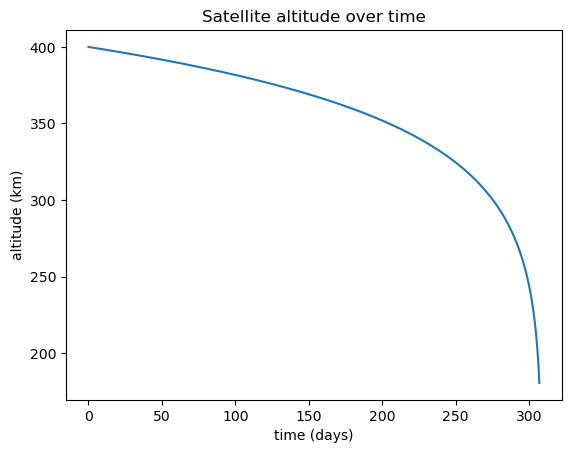

In [11]:
plt.plot(days, height)
plt.xlabel('time (days)')
plt.ylabel('altitude (km)')
plt.title('Satellite altitude over time')
plt.show()

Here, we can see that the satellite has a lifespan of approx. 307 days, and this lifespan is modelled in the graph.

## Changing altitude

Now, I will vary the starting altitude while holding mass and cross-sectional area constant. We will use starting altitudes of 200, 250, 300, 350, 400, 450, and 500 km.

In [12]:
A = 1. # cross-sectional area in m^2 -- input
Ae = A * Cd
m_sat = 250 # satellite mass in kg -- input

In [13]:
h_km = 200.
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

In [14]:
hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

the total lifespan for this satellite is 1.375 days


In [15]:
length_height = len(height)
height = np.delete(height, length_height-1)

In [16]:
hours_200 = hours
height_200 = height
time_tot_200 = time_tot

In [17]:
h_km = 250.
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_250 = hours
height_250 = height
time_tot_250 = time_tot

the total lifespan for this satellite is 9.958333333333334 days


In [18]:
h_km = 300.

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_300 = hours
height_300 = height
time_tot_300 = time_tot

the total lifespan for this satellite is 37.625 days


In [19]:
h_km = 350.

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_350 = hours
height_350 = height
time_tot_350 = time_tot

the total lifespan for this satellite is 121.95833333333333 days


In [20]:
h_km = 400.

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_400 = hours
height_400 = height
time_tot_400 = time_tot

the total lifespan for this satellite is 365.4583333333333 days


In [21]:
h_km = 450.

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_450 = hours
height_450 = height
time_tot_450 = time_tot

the total lifespan for this satellite is 1030.75 days


In [22]:
h_km = 500.

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_500 = hours
height_500 = height
time_tot_500 = time_tot

the total lifespan for this satellite is 2750.6666666666665 days


In [23]:
day_200 = []
for hour in hours_200:
    day = hour / 24
    day_200.append(day)

day_250 = []
for hour in hours_250:
    day = hour / 24
    day_250.append(day)

day_300 = []
for hour in hours_300:
    day = hour / 24
    day_300.append(day)

day_350 = []
for hour in hours_350:
    day = hour / 24
    day_350.append(day)

day_400 = []
for hour in hours_400:
    day = hour / 24
    day_400.append(day)

day_450 = []
for hour in hours_450:
    day = hour / 24
    day_450.append(day)

day_500 = []
for hour in hours_500:
    day = hour / 24
    day_500.append(day)

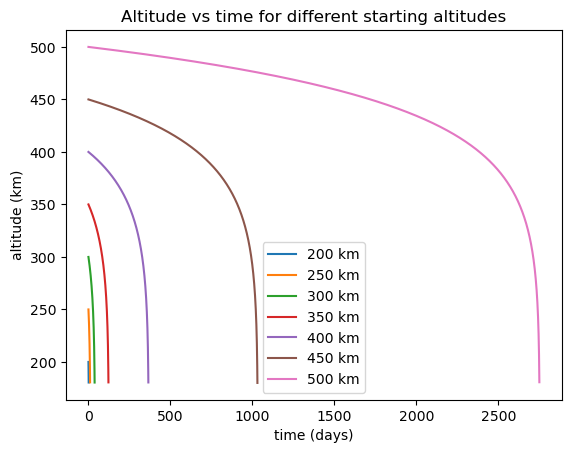

In [24]:
plt.plot(day_200, height_200, label = '200 km')
plt.plot(day_250, height_250, label = '250 km')
plt.plot(day_300, height_300, label = '300 km')
plt.plot(day_350, height_350, label = '350 km')
plt.plot(day_400, height_400, label = '400 km')
plt.plot(day_450, height_450, label = '450 km')
plt.plot(day_500, height_500, label = '500 km')
plt.xlabel('time (days)')
plt.ylabel('altitude (km)')
plt.title('Altitude vs time for different starting altitudes')
plt.legend()
plt.show()

As we can see from the plot that a higher starting altitude will have a longer lifespan.

## Changing Area

Now, I will change the cross-sectional area of the satellite while holding mass and starting altitude constant. The areas we use are 0.1, 0.5, 1, and 5 m $^2$.

In [25]:
m_sat = 100 # satellite mass in kg -- input

In [26]:
A = 0.1 # cross-sectional area in m^2 -- input
Ae = A * Cd

In [27]:
h_km = 400. # starting altitude in km -- input

hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_1 = hours
height_1 = height
time_1 = time_tot

the total lifespan for this satellite is 1461.625 days


In [28]:
A = 0.5 # cross-sectional area in m^2 -- input
Ae = A * Cd
h_km = 400.

In [29]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_2 = hours
height_2 = height
time_2 = time_tot

the total lifespan for this satellite is 292.375 days


In [30]:
A = 1. # cross-sectional area in m^2 -- input
Ae = A * Cd
h_km = 400.

In [31]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_3 = hours
height_3 = height
time_3 = time_tot

the total lifespan for this satellite is 146.25 days


In [32]:
A = 5. # cross-sectional area in m^2 -- input
Ae = A * Cd
h_km = 400.

In [33]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_4 = hours
height_4 = height
time_4 = time_tot

the total lifespan for this satellite is 29.291666666666668 days


In [34]:
day_1 = []
for hour in hours_1:
    day = hour / 24
    day_1.append(day)

day_2 = []
for hour in hours_2:
    day = hour / 24
    day_2.append(day)

day_3 = []
for hour in hours_3:
    day = hour / 24
    day_3.append(day)

day_4 = []
for hour in hours_4:
    day = hour / 24
    day_4.append(day)

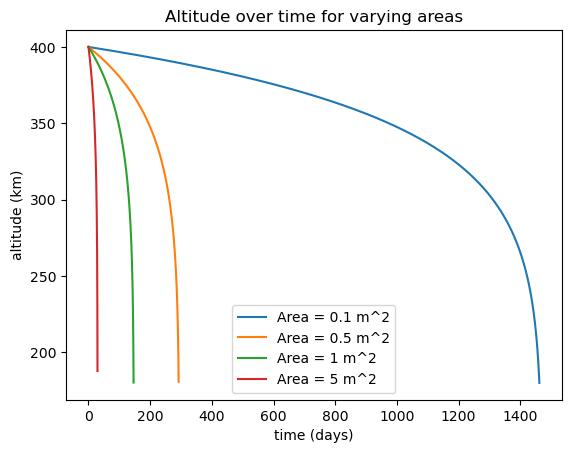

In [35]:
plt.plot(day_1, height_1, label = 'Area = 0.1 m^2')
plt.plot(day_2, height_2, label = 'Area = 0.5 m^2')
plt.plot(day_3, height_3, label = 'Area = 1 m^2')
plt.plot(day_4, height_4, label = 'Area = 5 m^2')
plt.legend()
plt.xlabel('time (days)')
plt.ylabel('altitude (km)')
plt.title('Altitude over time for varying areas')
plt.show()

From the plot, we can deduce that a smaller cross-sectional area means a longer lifespan, if we hold mass and starting altitude constant across the trials.

## Changing Mass

Now, we will change the mass holding starting altitude and cross-sectional area constant. The masses we use are 10, 50, 100, 300, and 500 kg.

In [36]:
A = 1. # cross-sectional area in m^2 -- input
Ae = A * Cd

In [37]:
h_km = 400. # starting altitude in km -- input
m_sat = 10. # satellite mass in kg -- input

In [38]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_10 = hours
height_10 = height
time_10 = time_tot

day_10 = []
for hour in hours_10:
    day = hour / 24
    day_10.append(day)

the total lifespan for this satellite is 14.708333333333334 days


In [39]:
h_km = 400. # starting altitude in km -- input
m_sat = 50. # satellite mass in kg -- input

In [40]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_50 = hours
height_50 = height
time_50 = time_tot

day_50 = []
for hour in hours_50:
    day = hour / 24
    day_50.append(day)

the total lifespan for this satellite is 73.16666666666667 days


In [41]:
h_km = 400. # starting altitude in km -- input
m_sat = 100. # satellite mass in kg -- input

In [42]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_100 = hours
height_100 = height
time_100 = time_tot

day_100 = []
for hour in hours_100:
    day = hour / 24
    day_100.append(day)

the total lifespan for this satellite is 146.25 days


In [43]:
h_km = 400. # starting altitude in km -- input
m_sat = 300. # satellite mass in kg -- input

In [44]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_300 = hours
height_300 = height
time_300 = time_tot

day_300 = []
for hour in hours_300:
    day = hour / 24
    day_300.append(day)

the total lifespan for this satellite is 438.5416666666667 days


In [45]:
h_km = 400. # starting altitude in km -- input
m_sat = 500. # satellite mass in kg -- input

In [46]:
hours = np.array([])
height = np.array([h_km])
hour = 0
while h_km > 180:
    hours = np.append(hours, hour)
    h_km_new = main(h_km)
    height = np.append(height, h_km_new)
    h_km = h_km_new
    hour += 1

hour_f = hour - 1
time_tot = hour_f / 24
print('the total lifespan for this satellite is '+str(time_tot)+' days')

length_height = len(height)
height = np.delete(height, length_height-1)

hours_500 = hours
height_500 = height
time_500 = time_tot

day_500 = []
for hour in hours_500:
    day = hour / 24
    day_500.append(day)

the total lifespan for this satellite is 730.8333333333334 days


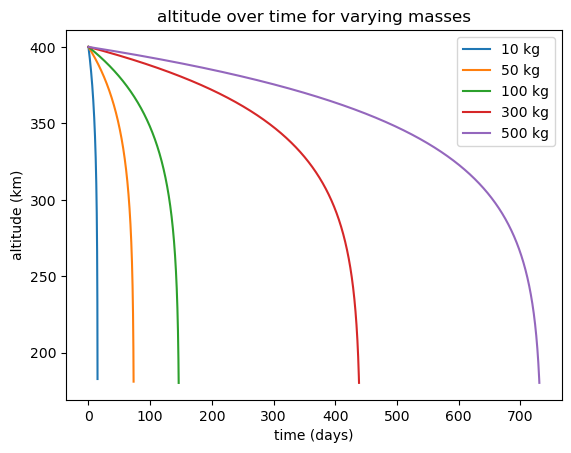

In [47]:
plt.plot(day_10, height_10, label = '10 kg')
plt.plot(day_50, height_50, label = '50 kg')
plt.plot(day_100, height_100, label = '100 kg')
plt.plot(day_300, height_300, label = '300 kg')
plt.plot(day_500, height_500, label = '500 kg')
plt.legend()
plt.xlabel('time (days)')
plt.ylabel('altitude (km)')
plt.title('altitude over time for varying masses')
plt.show()

From this plot, we can see that higher mass means longer lifespan.

From these calculations, we can see how mass, cross-sectional area, and starting altitude affect satellite decay. Lifespan increases with starting altitude and mass, and decreases with cross-sectional area. Because mass and area enter the decay equation as the ratio A/m, lifespan scales linearly with mass-to-area ratio: doubling the mass or halving the area doubles the lifespan. For the longest lifespan, we want a high starting altitude and a large mass relative to cross-sectional area.